In [ ]:
# =============================================================================
# Step 1 : Setup & Data Preparation
# =============================================================================

# Step 1.1 : Environment Setup & Import tools
import sys, os
import time
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

drive_root = '/content/drive/My Drive'

if drive_root not in sys.path:
    sys.path.append(drive_root)

from cs231nMe import *

%matplotlib inline

plt.rcParams["figure.figsize"] = (10.0, 8.0)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

# Step 1.3 : Download Dataset - CIFAR10
FOLDERNAME = 'cs231nMe'
current_working_dir = !pwd
current_working_dir = current_working_dir[0]

dataset_dir = f'/content/drive/My Drive/{FOLDERNAME}/datasets'
!mkdir -p "{dataset_dir}"
%cd "{dataset_dir}"

# Only download if it's not already there — safe to re-run
import os
if not os.path.exists('cifar-10-batches-py'):
    !wget -q http://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz
    !tar -xzf cifar-10-python.tar.gz
    print("Downloaded and extracted CIFAR-10.")
else:
    print("CIFAR-10 already present, skipping download.")

%cd {current_working_dir}

# Step 1.4 : Load Dataset
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

# Step 1.5 : Prepare & Create Data -> reshape + mean-subtraction normalization,
# then package the split subsets the solver will train/validate on.
X_train_vectorized = data["X_train"].reshape(data["X_train"].shape[0], -1)
X_val_vectorized = data["X_val"].reshape(data["X_val"].shape[0], -1)
X_test_vectorized = data["X_test"].reshape(data["X_test"].shape[0], -1)

mean_image = np.mean(X_train_vectorized, axis=0)
X_train_vectorized -= mean_image
X_val_vectorized -= mean_image
X_test_vectorized -= mean_image

# A small part for FUNCTIONALITY TEST like overfitting and etc tests befor a full training run.
num_train_small = 50

small_data = {
    "X_train": X_train_vectorized[:num_train_small],
    "y_train": data["y_train"][:num_train_small],
    "X_val": X_val_vectorized,
    "y_val": data["y_val"],
}

full_data = {
    "X_train": X_train_vectorized,
    "y_train": data["y_train"],
    "X_val": X_val_vectorized,
    "y_val": data["y_val"],
}


Mounted at /content/drive
/content/drive/My Drive/cs231nMe/datasets
CIFAR-10 already present, skipping download.
/content
X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


In [ ]:
# =============================================================================
# Step 2 : Model Creation & Initialization  (runs once)
# =============================================================================

# Step 2.1 & 2.2 : Define Architecture & Create Layer Dimensions
input_dim = X_train_vectorized.shape[1] # .shape[1] => Num of features or number of pixels in 1 images ( 3. 32 .32 = 3072)
hidden_dims = [100, 100]
num_classes = 10

# Step 2.3 : Initialize Parameters (W, b, and gamma/beta if normalization is used)
# -- happens inside FullyConnectedNet.__init__ when the model object is built:
model = FullyConnectedNet(
    hidden_dims,
    input_dim=input_dim,
    num_classes=num_classes,
    reg=1e-2,
    weight_scale=5e-2,
    dtype=np.float64,
    normalization="batchnorm",   # set to None to disable
    dropout_keep_ratio=0.9,      # set to 1 to disable dropout
)


(Iteration 1 / 4900) loss: 6.363038
(Epoch 0 / 10) train acc: 0.143000; val_acc: 0.137000
(Iteration 101 / 4900) loss: 2.666241
(Iteration 201 / 4900) loss: 2.056925
(Iteration 301 / 4900) loss: 1.874084
(Iteration 401 / 4900) loss: 1.837900
(Epoch 1 / 10) train acc: 0.436000; val_acc: 0.451000
(Iteration 501 / 4900) loss: 1.852275
(Iteration 601 / 4900) loss: 1.840201
(Iteration 701 / 4900) loss: 1.698772
(Iteration 801 / 4900) loss: 1.826208
(Iteration 901 / 4900) loss: 1.698770
(Epoch 2 / 10) train acc: 0.470000; val_acc: 0.458000
(Iteration 1001 / 4900) loss: 1.601714
(Iteration 1101 / 4900) loss: 1.633387
(Iteration 1201 / 4900) loss: 1.567321
(Iteration 1301 / 4900) loss: 1.647805
(Iteration 1401 / 4900) loss: 1.869922
(Epoch 3 / 10) train acc: 0.421000; val_acc: 0.444000
(Iteration 1501 / 4900) loss: 1.498407
(Iteration 1601 / 4900) loss: 1.806904
(Iteration 1701 / 4900) loss: 1.601784
(Iteration 1801 / 4900) loss: 1.772003
(Iteration 1901 / 4900) loss: 1.653183
(Epoch 4 / 10) t

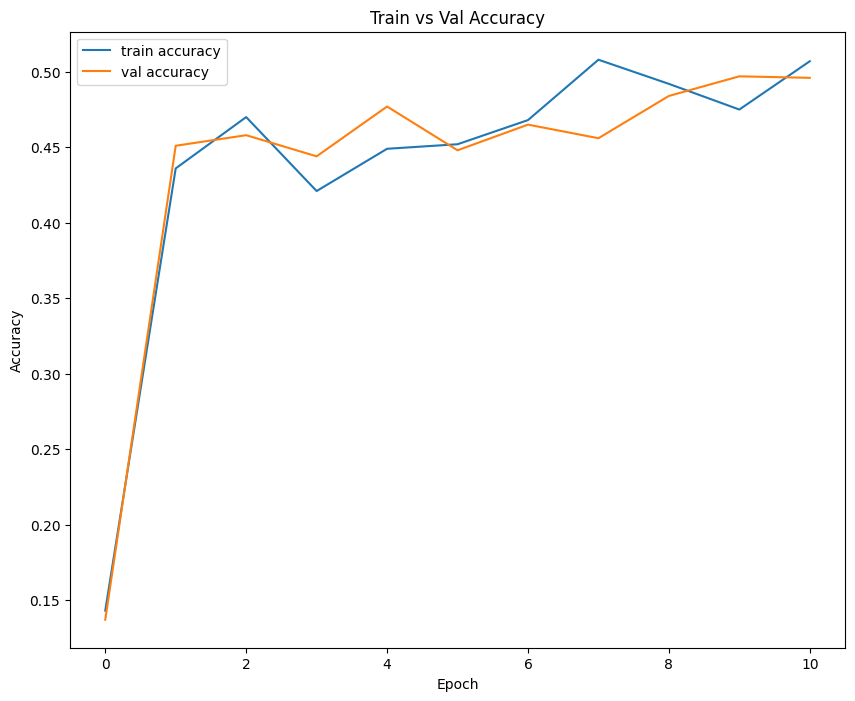

In [ ]:
# =============================================================================
# Step 3 : Training Setup & Mini-Batch
# =============================================================================

# Step 3.1 : Select training data
# We can change full_data to small_data to check overfitting
train_data = full_data

# Step 3.2 : Training Hyperparameters
learning_rate = 1e-3
batch_size = 100
num_epochs = 10

# Step 3.3 : Create Solver -> wraps model + data + hyperparameters together.
# This does NOT rebuild the model — it reuses the one created in Step 2.
solver = Solver(
    model,
    train_data,
    update_rule="adam",
    optim_config={"learning_rate": learning_rate},
    lr_decay=0.95,
    batch_size=batch_size,
    num_epochs=num_epochs,
    print_every=100,
)

# Step 3.4 : Start Mini-Batch  <- loop begins here, repeats each iteration
# Calling solver.train() runs Steps 3.4 -> 7.4 in a loop internally:
# sample mini-batch -> forward pass -> loss -> backward pass -> optimizer
# update -> back to 3.4, until num_epochs is reached.
solver.train()

plt.plot(solver.train_acc_history, label='train accuracy')
plt.plot(solver.val_acc_history, label='val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Train vs Val Accuracy')
plt.show()



In [1]:
# --- Step 4 setup: real mini-batch, model in train mode ---

np.random.seed(231)

# among all number of images (train_data["X_train"].shape[0]) choose number in batch size RANDOMLY.
batch_mask = np.random.choice(train_data["X_train"].shape[0], batch_size)

# From dic of train_data choose all images of training, then choose among them in number of batch_mask
X = train_data["X_train"][batch_mask]
y = train_data["y_train"][batch_mask]

# repeats once per hidden layer
# From the first iteration, we turn off some neurons randomly (dropout).
# Each iteration, we change them and turn off a different random group,
# so no single neuron becomes too dependent on the others.
model.dropout_param["mode"] = "train"

# For each hidden layer we have a batch normalization, so we change the mode of all layers to training
# beacause in training mode we use mean of that batch not all of batch
for bn_param in model.bn_params:
    bn_param["mode"] = "train"

# Step 4 (manual/unrolled version) — now matching FullyConnectedNet.loss() exactly
# Step 4.1 : Prepare Input
# Copy X into a new variable "out"
out = X
affine_caches, norm_caches, relu_caches, dropout_caches = [], [], [], []

# Step 4.2 : Hidden Layer Forward -- affine -> batchnorm -> relu -> dropout,
# repeats once per hidden layer
for i in range(1, model.num_layers):
    W = model.params[f"W{i}"]
    b = model.params[f"b{i}"]

    a, affine_cache = affine_forward(out, W, b)
    affine_caches.append(affine_cache)
# ___________________________________________________
    gamma = model.params[f"gamma{i}"]
    beta = model.params[f"beta{i}"]

    a, norm_cache = batchnorm_forward(a, gamma, beta, model.bn_params[i - 1])
    norm_caches.append(norm_cache)
# ___________________________________________________
    relu_out, relu_cache = relu_forward(a)
    relu_caches.append(relu_cache)

# ___________________________________________________
    relu_out, dropout_cache = dropout_forward(relu_out, model.dropout_param)
    dropout_caches.append(dropout_cache)

    out = relu_out
    print(f"  hidden layer {i} output shape: {out.shape}")

#____________________________________________________

# Step 4.3 : Final Output Layer -- affine only, no relu/norm/dropout
W_last = model.params[f"W{model.num_layers}"]
b_last = model.params[f"b{model.num_layers}"]
scores, final_cache = affine_forward(out, W_last, b_last)

# Step 4.4 : Scores
print("Final scores shape:", scores.shape)


NameError: name 'np' is not defined

In [3]:
# Step 5 : Loss Calculation

# Step 5.1 : Softmax(scores)
# numerical stability => each score - max score    # keepdims=True => to make -/+ possible
shifted_scores = scores - np.max(scores, axis=1, keepdims=True)

# Exp => we have smaller scores and some negative scores => exp(-scores) is positive and small
exp_scores = np.exp(shifted_scores)

# class probabilities
probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

print("Probabilities shape:", probs.shape)   # (N, C)

# Sum of all probs for each image and sum = 1 --> axis = 1 --> add across the row" (left to right) --> axis=0 would mean "add down the column"
print("Each row sums to 1:", np.sum(probs, axis=1))

#__________________________________________________________________
# Step 5.2 : Select Correct-Class Probabilities
N = scores.shape[0]

# first --> go to a row --> inside it, print the real value of correct class
correct_class_probs = probs[np.arange(N), y]
print("Correct-class probabilities:", correct_class_probs)

# Step 5.3 => data loss : sum all correct class --> -log () --> /N
# CrossEntropic => for classification
# MSE => Regression
data_loss = -np.sum(np.log(correct_class_probs)) / N
print("Data loss:", data_loss)

# Step 5.4 : L2 Regularization Loss
# 0.5 * reg * sum(W^2), summed across every weight matrix in the network
reg_loss = 0.0
for i in range(1, model.num_layers + 1):
    # get the matrix of weight of layer i from a dict
    W = model.params[f"W{i}"]
    # in another file "FullyConnectedNet.__init__" we have --> self.reg = reg (Step 2 --> reg = 1e-2 )
    reg_loss += 0.5 * model.reg * np.sum(W * W)
print("Regularization loss:", reg_loss)

# Step 5.5 : Total Loss + dout ready -> Backward Pass
total_loss = data_loss + reg_loss
print("Total loss:", total_loss)

# dout — the gradient of the loss w.r.t. scores, ready to hand to Step 6.
# For softmax + cross-entropy this has a clean closed form:
# probs, minus 1 at the correct class, averaged over the batch.
dout = probs.copy()
#choose the value of each row(image) from correct class(y)
dout[np.arange(N), y] -= 1
dout /= N
print("dout shape:", dout.shape)   # same shape as scores -> (N, C)

NameError: name 'scores' is not defined

In [ ]:
## Step 6 : Backward Pass & Gradient

grads = {}

# Step 6.1 : Receive dout from Softmax
# dout computed at the end of Step 5

# Step 6.2 : Final Affine Backward

#dout : how much wrong the out is  #dw_last : How much W needs change  #db_last : how much B needs changes
dout, dW_last, db_last = affine_backward(dout, final_cache)

# Aim :  how much W and B in the last layer needs to change
dW_last += model.reg * model.params[f"W{model.num_layers}"]

grads[f"W{model.num_layers}"] = dW_last
grads[f"b{model.num_layers}"] = db_last
print(f"  W{model.num_layers} grad shape:", dW_last.shape)

# Step 6.3 : Backward through Hidden Layers -- dropout -> relu -> batchnorm -> affine,
# repeats in reverse for each hidden layer
# PRESENTAION : This loop applies the chain rule backward through each hidden layer (dropout → ReLU → batchnorm → affine)
# to compute gradients for W, b, gamma, and beta.
for i in range(model.num_layers - 1, 0, -1):
    dout = dropout_backward(dout, dropout_caches[i - 1])
    dout = relu_backward(dout, relu_caches[i - 1])

    dout, dgamma, dbeta = batchnorm_backward_alt(dout, norm_caches[i - 1])
    grads[f"gamma{i}"] = dgamma
    grads[f"beta{i}"] = dbeta

    dout, dW, db = affine_backward(dout, affine_caches[i - 1])
    dW += model.reg * model.params[f"W{i}"]
    grads[f"W{i}"] = dW
    grads[f"b{i}"] = db
    print(f"  W{i} grad shape:", dW.shape, f" gamma{i} grad shape:", dgamma.shape)

# Step 6.4 : All Gradients Ready -> return loss, grads
print("Gradient keys:", sorted(grads.keys()))

  W3 grad shape: (100, 10)
  W2 grad shape: (100, 100)  gamma2 grad shape: (100,)
  W1 grad shape: (3072, 100)  gamma1 grad shape: (100,)
Gradient keys: ['W1', 'W2', 'W3', 'b1', 'b2', 'b3', 'beta1', 'beta2', 'gamma1', 'gamma2']


In [ ]:
# Step 7 : Optimizer & Parameter Update

# Step 7.1 : Receive Current Parameters (w, dw, config)
update_rule = adam            # swap for sgd / sgd_momentum / rmsprop
learning_rate = 1e-3

# optim_configs holds one config dict per parameter, so each parameter
# (W1, b1, W2, b2, ...) tracks its own momentum/cache/m/v state independently.
if "optim_configs" not in dir():
    optim_configs = {}
    for p in model.params:
        optim_configs[p] = {"learning_rate": learning_rate}

# Step 7.2 : Choose Update Rule  <- SGD / Momentum / RMSProp / Adam
# already chosen above via `update_rule` — swap the function reference to change it

# Step 7.3 : Compute Next Parameters
next_params = {}
for p, w in model.params.items():
    dw = grads[p]
    config = optim_configs[p]
    next_w, next_config = update_rule(w, dw, config)
    next_params[p] = next_w
    optim_configs[p] = next_config
    print(f"  {p} updated, config keys: {list(next_config.keys())}")

# Step 7.4 : Update Model Parameters -> loop back to Step 3.4 for next mini-batch
model.params = next_params
print("Parameters updated for this iteration.")

  W1 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  b1 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  gamma1 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  beta1 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  W2 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  b2 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  gamma2 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  beta2 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  W3 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
  b3 updated, config keys: ['learning_rate', 'beta1', 'beta2', 'epsilon', 'm', 'v', 't']
Parameters updated for this iteration.
